# StyleBot - Entrega 2: experimento controlado de aumento de datos

**Responsable:** Krysto Alberto Adan Jauregui Zuñiga  
**Semilla:** 42

Este notebook compara la misma arquitectura CNN entrenada bajo dos condiciones: sin aumento de datos y con aumento de datos. Se mantienen iguales la división, la arquitectura, el optimizador, el tamaño de lote y el número máximo de épocas. La comparación utiliza validación; el conjunto de prueba no se usa para seleccionar el modelo.

In [1]:
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

SEMILLA = 42
BATCH_SIZE = 128
EPOCAS = 8
random.seed(SEMILLA)
np.random.seed(SEMILLA)
tf.keras.utils.set_random_seed(SEMILLA)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

print('TensorFlow:', tf.__version__)
print('Semilla:', SEMILLA)
print('Épocas máximas:', EPOCAS)
print('Batch size:', BATCH_SIZE)

TensorFlow: 2.21.0
Semilla: 42
Épocas máximas: 8
Batch size: 128


## 1. Preparación común de Fashion-MNIST

Se conserva el protocolo de `00_datos_cnn.ipynb`: 48,000 imágenes para entrenamiento, 12,000 para validación y 10,000 para prueba, con semilla 42 y estratificación.

In [2]:
(X_base, y_base), (X_test_original, y_test) = tf.keras.datasets.fashion_mnist.load_data()
indices = np.arange(len(y_base), dtype=np.int64)
idx_train, idx_val = train_test_split(
    indices, test_size=0.20, random_state=SEMILLA, stratify=y_base
)

X_train = (X_base[idx_train].astype('float32') / 255.0)[..., np.newaxis]
y_train = y_base[idx_train].astype('int64')
X_val = (X_base[idx_val].astype('float32') / 255.0)[..., np.newaxis]
y_val = y_base[idx_val].astype('int64')
X_test = (X_test_original.astype('float32') / 255.0)[..., np.newaxis]
y_test = y_test.astype('int64')

assert X_train.shape == (48000, 28, 28, 1)
assert X_val.shape == (12000, 28, 28, 1)
assert X_test.shape == (10000, 28, 28, 1)
print('Entrenamiento:', X_train.shape)
print('Validación:   ', X_val.shape)
print('Prueba:       ', X_test.shape)
print('Prueba reservada: no se utilizará en este experimento.')

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Entrenamiento: (48000, 28, 28, 1)
Validación:    (12000, 28, 28, 1)
Prueba:        (10000, 28, 28, 1)
Prueba reservada: no se utilizará en este experimento.


## 2. Condiciones controladas

La arquitectura base es idéntica en ambos entrenamientos. El aumento incluye rotación, traslación y zoom pequeños y solamente se aplica al conjunto de entrenamiento.

In [3]:
aumento_datos = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05, fill_mode='nearest', seed=SEMILLA),
    tf.keras.layers.RandomTranslation(0.05, 0.05, fill_mode='nearest', seed=SEMILLA),
    tf.keras.layers.RandomZoom(0.05, fill_mode='nearest', seed=SEMILLA),
], name='aumento_solo_entrenamiento')

def crear_modelo_base():
    tf.keras.utils.set_random_seed(SEMILLA)
    modelo = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28, 1)),
        tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax'),
    ], name='cnn_controlada')
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return modelo

AUTOTUNE = tf.data.AUTOTUNE
train_sin_aumento = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(len(X_train), seed=SEMILLA, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
train_con_aumento = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(len(X_train), seed=SEMILLA, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .map(lambda imagenes, etiquetas: (aumento_datos(imagenes, training=True), etiquetas),
         num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE).prefetch(AUTOTUNE)

modelo_verificacion = crear_modelo_base()
print('Parámetros de la arquitectura común:', modelo_verificacion.count_params())
print('Condición 1: entrenamiento sin aumento')
print('Condición 2: entrenamiento con aumento')
print('Validación: sin aumento en ambas condiciones')

Parámetros de la arquitectura común: 402442
Condición 1: entrenamiento sin aumento
Condición 2: entrenamiento con aumento
Validación: sin aumento en ambas condiciones


## 3. Entrenamiento y medición

Se entrenan dos copias nuevas del mismo modelo durante ocho épocas. Se registra el tiempo total y se calculan accuracy y F1 macro sobre validación.

In [4]:
def entrenar_y_evaluar(nombre, train_ds):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEMILLA)
    modelo = crear_modelo_base()
    inicio = time.perf_counter()
    historial = modelo.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCAS,
        verbose=2
    )
    segundos = time.perf_counter() - inicio
    probabilidades = modelo.predict(val_ds, verbose=0)
    predicciones = np.argmax(probabilidades, axis=1)
    resultado = {
        'condición': nombre,
        'accuracy_validación': accuracy_score(y_val, predicciones),
        'f1_macro_validación': f1_score(y_val, predicciones, average='macro'),
        'tiempo_segundos': segundos,
        'parámetros': modelo.count_params(),
        'épocas': len(historial.history['loss'])
    }
    return modelo, historial, resultado

modelo_sin, historial_sin, resultado_sin = entrenar_y_evaluar(
    'Sin aumento', train_sin_aumento
)
modelo_con, historial_con, resultado_con = entrenar_y_evaluar(
    'Con aumento', train_con_aumento
)

resultados = pd.DataFrame([resultado_sin, resultado_con])
display(resultados.round(4))

Epoch 1/8
375/375 - 9s - 24ms/step - accuracy: 0.8307 - loss: 0.4927 - val_accuracy: 0.8736 - val_loss: 0.3688
Epoch 2/8
375/375 - 3s - 7ms/step - accuracy: 0.8855 - loss: 0.3245 - val_accuracy: 0.8915 - val_loss: 0.3054
Epoch 3/8
375/375 - 2s - 7ms/step - accuracy: 0.9004 - loss: 0.2794 - val_accuracy: 0.9014 - val_loss: 0.2773
Epoch 4/8
375/375 - 3s - 9ms/step - accuracy: 0.9105 - loss: 0.2502 - val_accuracy: 0.9098 - val_loss: 0.2610
Epoch 5/8
375/375 - 3s - 9ms/step - accuracy: 0.9164 - loss: 0.2290 - val_accuracy: 0.9103 - val_loss: 0.2551
Epoch 6/8
375/375 - 4s - 12ms/step - accuracy: 0.9231 - loss: 0.2111 - val_accuracy: 0.9082 - val_loss: 0.2586
Epoch 7/8
375/375 - 2s - 7ms/step - accuracy: 0.9305 - loss: 0.1926 - val_accuracy: 0.9147 - val_loss: 0.2432
Epoch 8/8
375/375 - 4s - 12ms/step - accuracy: 0.9336 - loss: 0.1818 - val_accuracy: 0.9187 - val_loss: 0.2397
Epoch 1/8
375/375 - 8s - 21ms/step - accuracy: 0.7530 - loss: 0.6838 - val_accuracy: 0.8106 - val_loss: 0.5139
Epoch 

,condición,accuracy_validación,f1_macro_validación,tiempo_segundos,parámetros,épocas
0,Sin aumento,0.9188,0.9183,32.9020,402442,8
1,Con aumento,0.8790,0.8793,58.2762,402442,8


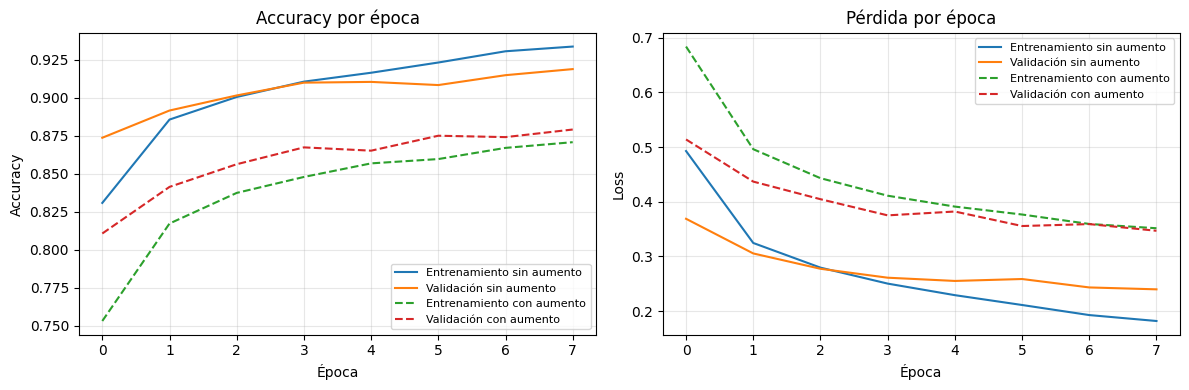

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(historial_sin.history['accuracy'], label='Entrenamiento sin aumento')
axes[0].plot(historial_sin.history['val_accuracy'], label='Validación sin aumento')
axes[0].plot(historial_con.history['accuracy'], '--', label='Entrenamiento con aumento')
axes[0].plot(historial_con.history['val_accuracy'], '--', label='Validación con aumento')
axes[0].set_title('Accuracy por época')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Accuracy')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].plot(historial_sin.history['loss'], label='Entrenamiento sin aumento')
axes[1].plot(historial_sin.history['val_loss'], label='Validación sin aumento')
axes[1].plot(historial_con.history['loss'], '--', label='Entrenamiento con aumento')
axes[1].plot(historial_con.history['val_loss'], '--', label='Validación con aumento')
axes[1].set_title('Pérdida por época')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Loss')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Conclusión automática y entrega al equipo

In [6]:
mejor_f1 = resultados.loc[resultados['f1_macro_validación'].idxmax()]
diferencia = resultado_con['f1_macro_validación'] - resultado_sin['f1_macro_validación']
print('Mejor condición en F1 macro de validación:', mejor_f1['condición'])
print('Diferencia F1 (con aumento - sin aumento):', round(diferencia, 4))
print('El conjunto de prueba permaneció reservado y no se utilizó para seleccionar.')
print('Variables disponibles para Juan José: X_train, y_train, X_val, y_val,')
print('X_test, y_test, train_con_aumento, train_sin_aumento y val_ds.')

Mejor condición en F1 macro de validación: Sin aumento
Diferencia F1 (con aumento - sin aumento): -0.039
El conjunto de prueba permaneció reservado y no se utilizó para seleccionar.
Variables disponibles para Juan José: X_train, y_train, X_val, y_val,
X_test, y_test, train_con_aumento, train_sin_aumento y val_ds.


### Configuración registrada

- Misma arquitectura en ambas condiciones.
- Optimizador Adam con tasa de aprendizaje 0.001.
- Pérdida sparse categorical crossentropy.
- Ocho épocas máximas.
- Tamaño de lote 128.
- Semilla 42.
- Validación sin aumento.
- Prueba reservada.

Este experimento sirve como evidencia del efecto del aumento bajo condiciones controladas. No sustituye el entrenamiento de las arquitecturas A, B y C asignado a Juan José.